In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [3]:
from src.conexao_banco import conn, cursor

- Primeira pergunta de negócio: Em quais dias e horários existe maior demanda por corridas?

In [4]:
query = """ 
    SELECT 
        EXTRACT('dow' from "Date") as Day_Of_Week,
		EXTRACT('hour' from "Time") as Hour,
        COUNT(*) as total_rides
    FROM ncr_ride_bookings
    GROUP BY Day_Of_Week, Hour
    ORDER BY Day_Of_Week, Hour
"""

In [5]:
dia_hora_demanda = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_19404\3250416968.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dia_hora_demanda = pd.read_sql_query(query, conn)


In [6]:
dia_hora_demanda['day_of_week'] = dia_hora_demanda['day_of_week'].astype(np.int64)
dia_hora_demanda['hour'] = dia_hora_demanda['hour'].astype(np.int64)
dia_hora_demanda['total_rides'] = dia_hora_demanda['total_rides'].astype(np.int64)

In [7]:
matriz_heatmap = dia_hora_demanda.pivot(
    index='day_of_week',
    columns='hour',
    values='total_rides'
)

In [8]:
matriz_heatmap

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_of_week,,,,,,,,,,,,,,,,,,,,,
0,199,191,179,202,193,364,559,791,971,1191,...,984,1111,1390,1581,1746,1630,1301,1184,783,368
1,202,209,205,202,181,444,589,761,1020,1199,...,996,1152,1380,1563,1820,1547,1412,1204,722,405
2,178,185,203,203,185,414,626,785,1020,1132,...,990,1191,1319,1529,1749,1583,1358,1160,790,375
3,207,185,192,178,183,366,615,765,931,1210,...,955,1159,1384,1598,1776,1551,1403,1098,781,424
4,207,195,182,197,167,396,572,770,932,1135,...,974,1222,1340,1566,1672,1537,1351,1132,781,387
5,177,185,189,203,203,373,585,760,978,1154,...,1034,1146,1401,1534,1752,1567,1357,1093,752,360
6,195,197,171,189,199,407,583,769,954,1149,...,1030,1158,1351,1591,1783,1548,1367,1160,788,420


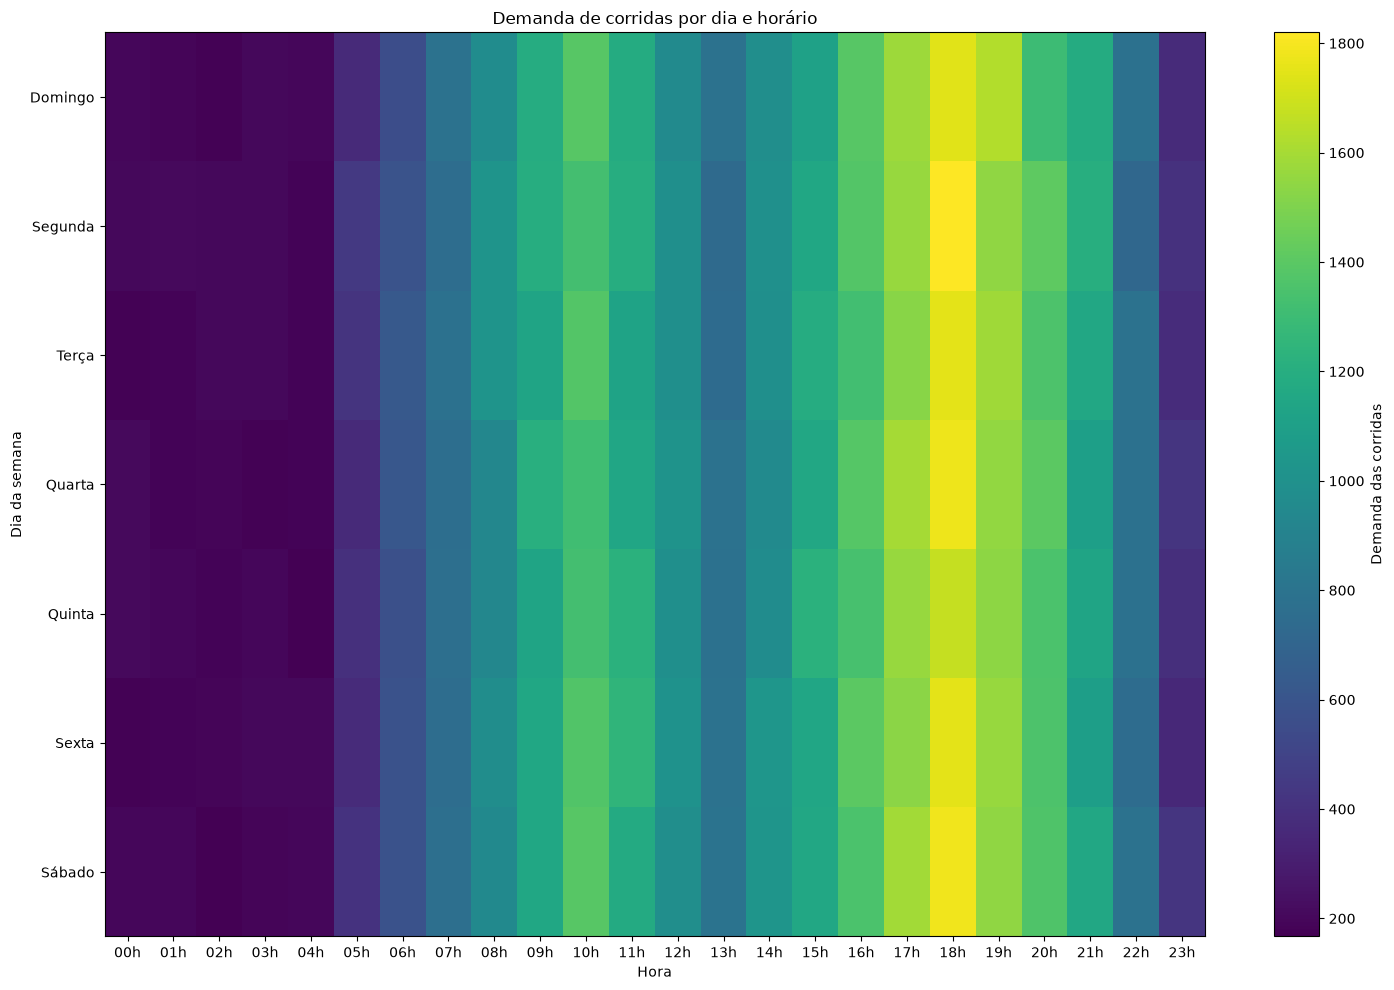

In [9]:
plt.figure(figsize=(15, 10))

plt.imshow(
    matriz_heatmap,
    aspect='auto'
)

plt.xticks(
    range(24),
    [f'{hora:02d}h' for hora in range(24)]
)

plt.yticks(
    range(7),
    ['Domingo', 'Segunda', 'Terça', 'Quarta',
     'Quinta', 'Sexta', 'Sábado']
)

plt.xlabel('Hora')
plt.ylabel('Dia da semana')
plt.title('Demanda de corridas por dia e horário')

plt.colorbar(label='Demanda das corridas')

plt.tight_layout()
plt.show()

    A análise do heatmap indica que o pico de demanda por corridas ocorre às 18h, com maior concentração de solicitações nesse horário ao longo da semana. Também é possível observar níveis elevados de demanda às 10h e entre 16h e 20h, sugerindo uma intensificação da atividade nesses períodos, independentemente do dia da semana.

- Segunda pergunta de negócio: Como o volume de corridas e o valor gerado variam ao longo do tempo?

In [10]:
query = """
    SELECT 
        EXTRACT('month' from "Date") as month,
        COUNT(*) as total_rides,
		SUM("Booking_Value") as total_booking_value
    FROM ncr_ride_bookings
	WHERE "Booking_Status" = 'Completed'
    GROUP BY month
    ORDER BY month
"""

In [11]:
data_demanda_valor_total = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_19404\3056684667.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  data_demanda_valor_total = pd.read_sql_query(query, conn)


In [12]:
data_demanda_valor_total['month'] = data_demanda_valor_total['month'].astype(np.int64)
data_demanda_valor_total['total_booking_value'] = data_demanda_valor_total['total_booking_value'].astype(np.int64)

In [13]:
mapeamento_meses = {
    1: "Janeiro",
    2: "Fevereiro",
    3: "Março",
    4: "Abril",
    5: "Maio",
    6: "Junho",
    7: "Julho",
    8: "Agosto",
    9: "Setembro",
    10: "Outubro",
    11: "Novembro",
    12: "Dezembro"
}

In [14]:
data_demanda_valor_total['month_name'] = data_demanda_valor_total['month'].map(mapeamento_meses)

In [15]:
data_demanda_valor_total = data_demanda_valor_total.drop(columns=['month'])

In [16]:
data_demanda_valor_total

,total_rides,total_booking_value,month_name
0,7871,3959989,Janeiro
1,7305,3713030,Fevereiro
2,7890,4143391,Março
3,7574,3857364,Abril
4,7835,3898836,Maio
5,7704,3939898,Junho
6,7869,3936701,Julho
7,7721,3839075,Agosto
8,7480,3786394,Setembro
9,7842,3974673,Outubro


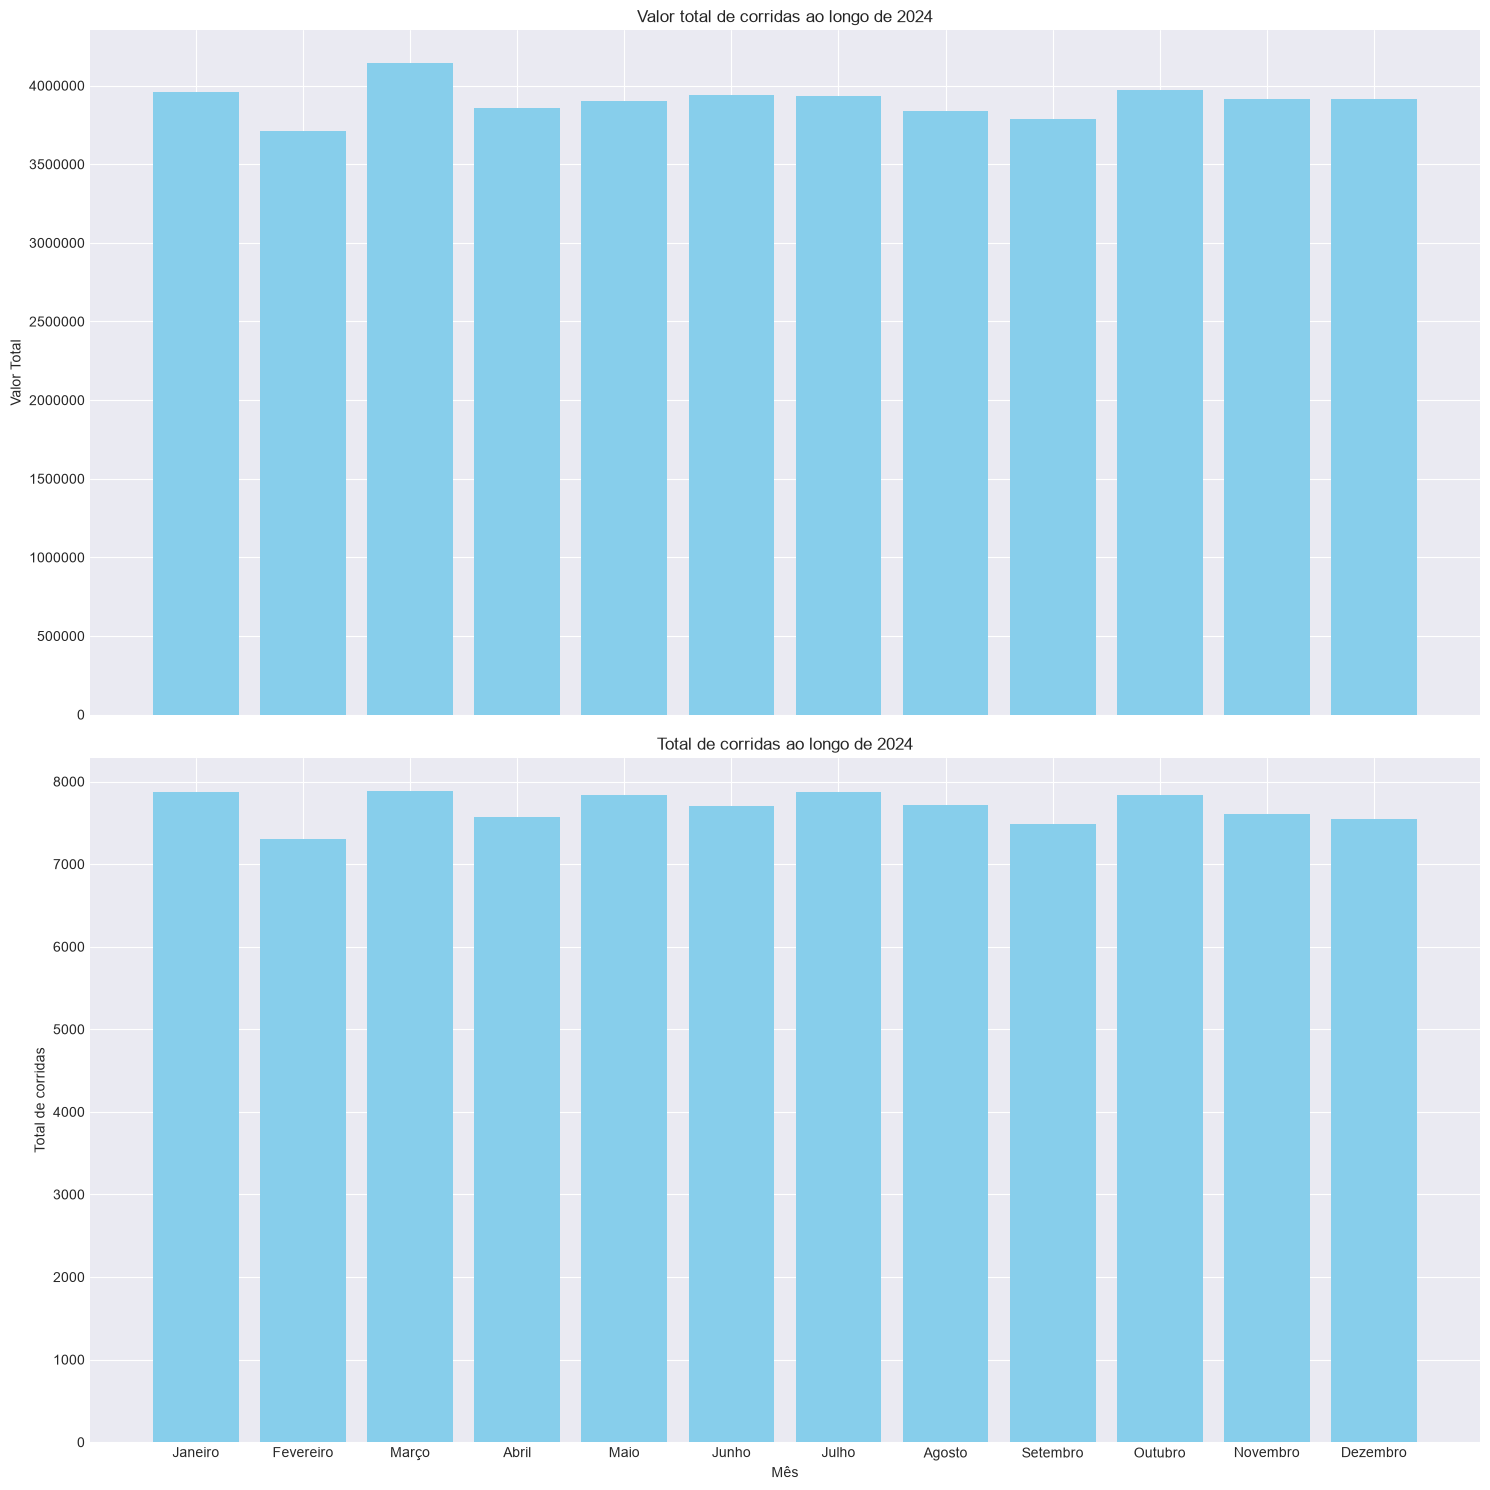

In [29]:
plt.style.use('seaborn-v0_8-darkgrid')

fig, (ax_cima, ax_baixo) = plt.subplots(figsize=(15, 15), nrows=2, sharex=True)

ax_cima.bar(data_demanda_valor_total['month_name'], data_demanda_valor_total['total_booking_value'], color='skyblue')

ax_cima.set_ylabel('Valor Total')
ax_cima.set_title('Valor total de corridas ao longo de 2024')
ax_cima.ticklabel_format(style='plain', axis='y')

ax_baixo.bar(data_demanda_valor_total['month_name'], data_demanda_valor_total['total_rides'], color='skyblue')

ax_baixo.set_xlabel('Mês')
ax_baixo.set_ylabel('Total de corridas')
ax_baixo.set_title('Total de corridas ao longo de 2024')

plt.tight_layout()
plt.show()

    Ao longo de 2024, o volume de corridas e o valor total gerado apresentaram pequenas variações mensais, mantendo-se relativamente estáveis durante o ano. Março se destacou pelo maior valor gerado e maior volume de corridas, enquanto fevereiro apresentou os menores valores em ambos os indicadores.